# Lab 6 Take-Home Assignment: Feature Engineering Pipeline

**Objective:** You will be given a dataset with mixed feature types. Your goal is to build a complete feature engineering pipeline. 

**Key Requirement:** Unlike the tutorial, you are **NOT** told exactly which technique to use for each feature. You must analyze the df (EDA), decide on the best transformation, and **justify your choice**.

**Dataset:** `Housing Prices` (Loaded from SQLite).

**Important:** The `Price` column is the **target variable** (what we want to predict). **Do NOT use `Price` in any feature selection or feature engineering steps** - it should only be used as the target (y) variable.

In [224]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from datetime import datetime
# %pip install category_encoders

# Load df from SQLite
conn = sqlite3.connect('lab6.db')
df = pd.read_sql('SELECT * FROM housing', conn)
conn.close()

# Drop HouseID
df = df.drop('HouseID', axis=1)

print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (500, 7)


,Price,SqFt,LotSize,YearBuilt,Condition,Neighborhood,ZipCode
0,570684.983940,2179.075590,59566.961953,2018,Excellent,Uptown,10044
1,362813.270878,2010.447483,292037.951766,1963,Good,Midtown,10037
2,390796.944648,1833.930920,186450.030474,1987,Good,Suburbs,10020
3,350382.575382,2559.824301,21913.263071,1995,Excellent,Midtown,10024
4,365111.794794,2635.024707,85713.311813,1998,Poor,Downtown,10015


## Task 0: Setup Logging
Copy the `DataTransformationLog` class from the tutorial and initialize it for this dataset.

In [225]:
# Paste DataTransformationLog class here
# Initialize: log = DataTransformationLog(dataset_name="Housing_Prices", analyst_name="Your Name")
class DataTransformationLog:
    """
    A comprehensive df cleaning logger that tracks all transformations
    """
    
    def __init__(self, dataset_name, analyst_name):
        self.dataset_name = dataset_name
        self.analyst_name = analyst_name
        self.start_time = datetime.now()
        self.log_entries = []
        self.summary_stats = {
            'initial': {},
            'final': {}
        }
        
    def log_action(self, category, action, details, rows_affected=None, 
                   columns_affected=None, before_value=None, after_value=None):
        """
        Log a df cleaning action
        """
        entry = {
            'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
            'category': category,
            'action': action,
            'details': details,
            'rows_affected': rows_affected,
            'columns_affected': columns_affected if columns_affected else [],
            'before_value': str(before_value) if before_value is not None else None,
            'after_value': str(after_value) if after_value is not None else None
        }
        self.log_entries.append(entry)
        
    def to_dataframe(self):
        """Convert log to DataFrame"""
        return pd.DataFrame(self.log_entries)

# Initialize Log
log = DataTransformationLog(dataset_name="Housing_Prices", analyst_name="MT & AM")
print("Log Initialized.")


Log Initialized.


## Task 1: Exploratory df Analysis (EDA)

**Step 1: Visualization**
Plot distributions (histograms) for numerical features (`SqFt`, `LotSize`).

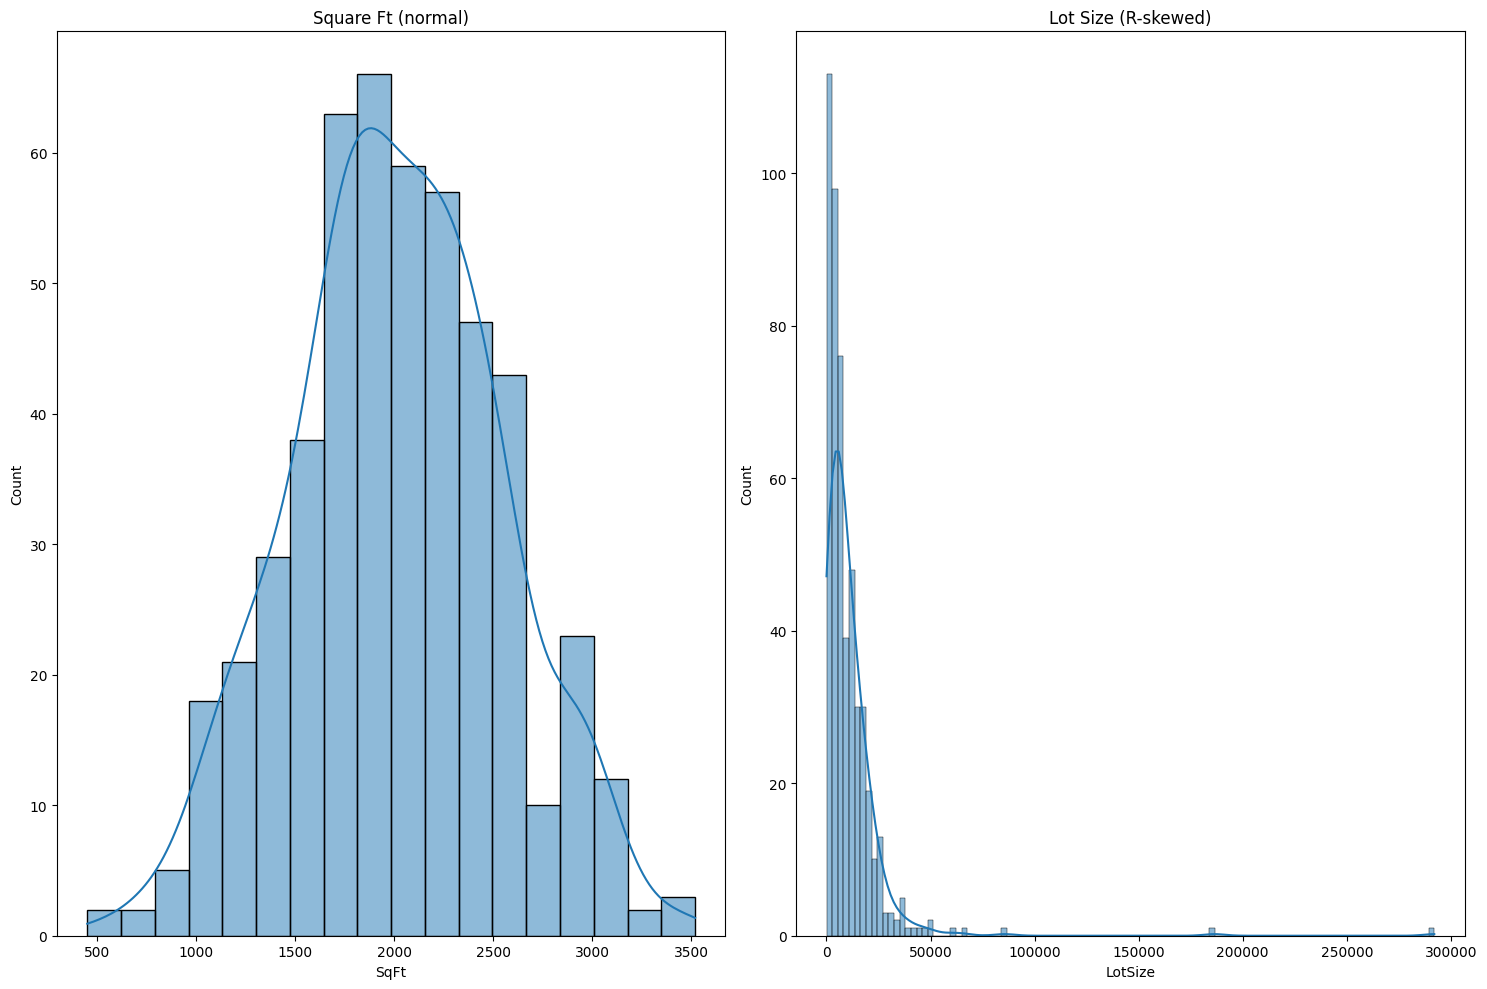

In [226]:
# Your EDA Code here (Plotting and Checking)
fig, axes = plt.subplots(1, 2, figsize=(15, 10))
sns.histplot(df['SqFt'], kde=True, ax=axes[0]).set_title('Square Ft (normal)')
sns.histplot(df['LotSize'], kde=True, ax=axes[1]).set_title('Lot Size (R-skewed)')

plt.tight_layout()
plt.show()

**Step 2: Conclusion**
Based on your plots, which feature is Normal and which is Skewed?

**Answer:** SqFt is normal & Lot Size is skewed

## Task 2: Feature Scaling

**Step 1: Selection**
Decide which scaler to use for `SqFt` and which for `LotSize` based on your EDA.

**Answer:** I will use Standardization for SqFt because distribusion is Normal and Robust Scaling for LotSize because distribusion is skewed

**Step 2: Implementation**
Apply the transformations and **log your actions**.

In [227]:
# Your Scaling Implementation here
from sklearn.preprocessing import StandardScaler, RobustScaler

scaler_std = StandardScaler()
df['SqFt_Scaled'] = scaler_std.fit_transform(df[['SqFt']])

log.log_action(
    category='Scaling',
    action='StandardScaler',
    details='Applied Z-Score standardization to SqFt (Normal distribution).',
    columns_affected=['SqFt']
)

print(f"SqFt Mean: {df['SqFt_Scaled'].mean():.2f}, Std: {df['SqFt_Scaled'].std():.2f}")
print(f"Min: {df['SqFt_Scaled'].min():.2f}, Max: {df['SqFt_Scaled'].max():.2f}")


scaler_robust = RobustScaler()
df['LotSize_Robust'] = scaler_robust.fit_transform(df[['LotSize']])

# Log the action
log.log_action(
    category='Scaling',
    action='RobustScaler',
    details='Applied Robust Scaling to LotSize to handle outliers.',
    columns_affected=['LotSize']
)

print(f"LotSize Mean: {df['LotSize_Robust'].mean():.2f}, Std: {df['LotSize_Robust'].std():.2f}")
print(f"Min: {df['LotSize_Robust'].min():.2f}, Max: {df['LotSize_Robust'].max():.2f}")


SqFt Mean: 0.00, Std: 1.00
Min: -2.97, Max: 2.86
LotSize Mean: 0.38, Std: 1.66
Min: -0.61, Max: 26.56


**Step 3: Verification**
Plot the distributions BEFORE and AFTER scaling to show the effect.

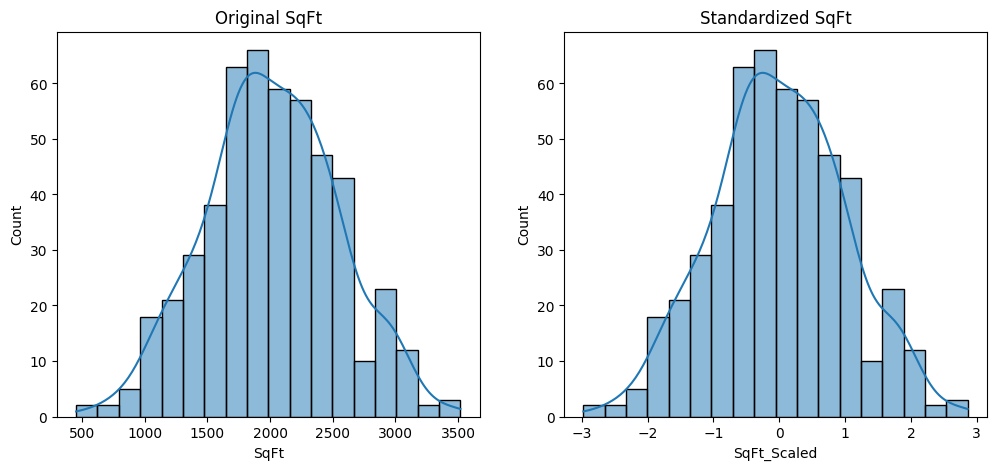

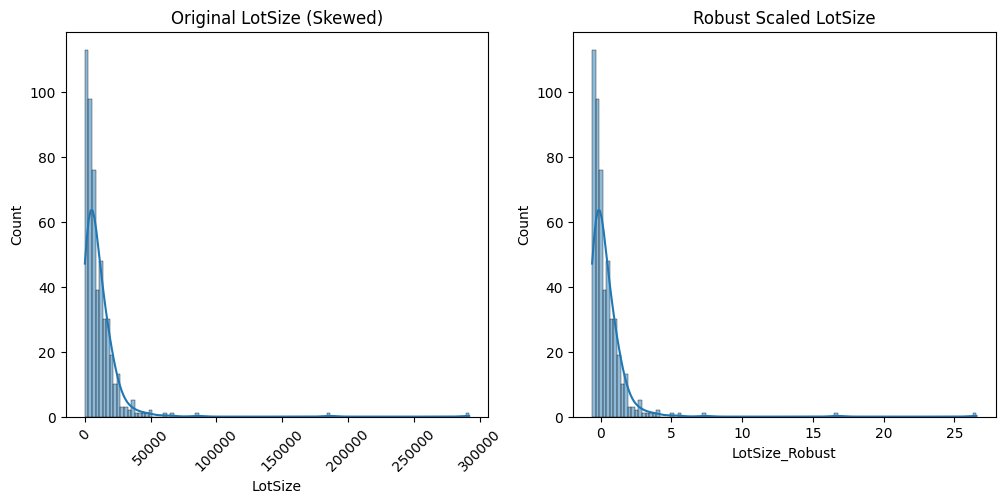

In [228]:
# Your Verification Plots here
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['SqFt'], kde=True).set_title("Original SqFt")
plt.subplot(1, 2, 2)
sns.histplot(df['SqFt_Scaled'], kde=True).set_title("Standardized SqFt")
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df['LotSize'], kde=True, ax=axes[0]).set_title('Original LotSize (Skewed)')
axes[0].tick_params(axis='x', rotation=45) # Rotate labels for better visibility

sns.histplot(df['LotSize_Robust'], kde=True, ax=axes[1]).set_title('Robust Scaled LotSize')
plt.show()

## Task 3: Feature Encoding

**Step 1: Analysis**
Check the number of unique values (cardinality) and the df type for `Neighborhood`, `Condition`, and `ZipCode`.
Determine if they are Nominal or Ordinal.

In [229]:
# Check cardinality and types
print(df[['Neighborhood', 'Condition', 'ZipCode']].nunique())
print(df[['Neighborhood', 'Condition', 'ZipCode']].dtypes)

Neighborhood     4
Condition        4
ZipCode         50
dtype: int64
Neighborhood      str
Condition         str
ZipCode         int64
dtype: object


**Step 2: Selection**
Based on your analysis, choose the encoding technique for each:
- `Neighborhood`: (Nominal/Ordinal? High/Low Cardinality?) -> Technique?
- `Condition`: (Nominal/Ordinal? High/Low Cardinality?) -> Technique?
- `ZipCode`: (Nominal/Ordinal? High/Low Cardinality?) -> Technique?

**Answer:** 
- `Neighborhood`: (Nominal Low Cardinality) -> One hot encoding
- `Condition`: (Ordinal Low Cardinality) -> Ordinal Encoding
- `ZipCode`: (Nominal High Cardinality) -> Binary encoding

**Step 3: Implementation**
Apply the encoders and **log your actions**.

In [230]:
# Your Encoding Implementation here
Neighborhood_encoded = pd.get_dummies(df['Neighborhood'], prefix='NGH', drop_first=True)
print(Neighborhood_encoded.head())

df = pd.concat([df, Neighborhood_encoded], axis=1)

# Log the action
log.log_action(
    category='Encoding',
    action='One-Hot Encoding',
    details='One-Hot encoded Neighborhood column.',
    columns_affected=['Neighborhood'],
    after_value=f"Created {Neighborhood_encoded.shape[1]} new columns"
)

   NGH_Midtown  NGH_Suburbs  NGH_Uptown
0        False        False        True
1         True        False       False
2        False         True       False
3         True        False       False
4        False        False       False


In [231]:
from sklearn.preprocessing import OrdinalEncoder

cond_order = [['Poor', 'Fair', 'Good', 'Excellent']]
encoder_ord = OrdinalEncoder(categories=cond_order)

df['Condition_Encoded'] = encoder_ord.fit_transform(df[['Condition']])
print(df[['Condition', 'Condition_Encoded']].head())

# Log the action
log.log_action(
    category='Encoding',
    action='Ordinal Encoding',
    details='Encoded Condition preserving ordinality.',
    columns_affected=['Condition']
)

   Condition  Condition_Encoded
0  Excellent                3.0
1       Good                2.0
2       Good                2.0
3  Excellent                3.0
4       Poor                0.0


In [232]:
import category_encoders as ce

encoder_bin = ce.BinaryEncoder(cols=['ZipCode'])

df_bin = encoder_bin.fit_transform(df[['ZipCode']])

print(f"Original Unique Roles: {df['ZipCode'].nunique()}")
print(f"Binary Encoded Columns: {df_bin.shape[1]}")
print(df_bin.head())

df = pd.concat([df, df_bin], axis=1)

# Log the action
log.log_action(
    category='Encoding',
    action='Binary Encoding',
    details='Binary encoded ZipCode (High Cardinality).',
    columns_affected=['ZipCode'],
    after_value=f"Created {df_bin.shape[1]} columns"
)

Original Unique Roles: 50
Binary Encoded Columns: 6
   ZipCode_0  ZipCode_1  ZipCode_2  ZipCode_3  ZipCode_4  ZipCode_5
0          0          0          0          0          0          1
1          0          0          0          0          1          0
2          0          0          0          0          1          1
3          0          0          0          1          0          0
4          0          0          0          1          0          1


## Task 4: Feature Interactions
**Instructions:**
Create **four** interaction features different from the tutorial examples.

1.  **Feature 1 (Boolean/Logical):** Create a binary flag called `Luxury_Estate`. Define it as a property that has `Condition` = 'Excellent' **AND** `LotSize` > (some threshold: 75th percentile).
2.  **Feature 2 (Temporal Subtraction):** Create a feature `House_Age` = Current Year - `YearBuilt`.
3.  **Feature 3 (Statistical Aggregation):** Create a feature that shows how each house's square footage compares to the overall average square footage in the dataset.
    - Calculate the overall mean of `SqFt` 
    - Create a feature like `SqFt_vs_Overall_Mean` = `SqFt` / mean(`SqFt`)
    - This captures whether a house is larger or smaller than the overall average (values > 1 = above average, < 1 = below average)
4.  **Feature 4 (Arithmetic Operation):** Create a feature `Total_Property_Size` = `SqFt` + `LotSize` (sum of indoor and outdoor space).

**Note**:  Use features after encoding and scaling

**Log all four actions**.

In [233]:
# Your Interaction Implementation here
threshold = df['LotSize'].max() * 0.75
print(threshold)

df['Luxury_Estate'] = ((df['Condition'] == 'Excellent') & (df['LotSize'] > threshold))
df['Luxury_Estate'].tail()

log.log_action(
    category='Feature Interaction',
    action='Create a binary flag called `Luxury_Estate`',
    details='Define it as a property that has `Condition` = Excellent **AND** `LotSize` > (some threshold: 75th percentile).',
    columns_affected=['Luxury_Estate']
)

219028.46382427702


In [234]:
df['House_Age'] = 2026 - df['YearBuilt']
df['House_Age'].head()

log.log_action(
    category='Feature Interaction',
    action='Create a feature',
    details='`House_Age` = Current Year - `YearBuilt`',
    columns_affected=['House_Age']
)

In [235]:
mean = df['SqFt'].mean()
df['SqFt_vs_Overall_Mean'] = df['SqFt'] / mean
df['SqFt_vs_Overall_Mean'].head()

log.log_action(
    category='Feature Interaction',
    action='Create a feature that shows how each houses square footage compares to the overall average square footage in the dataset.',
    details='`SqFt_vs_Overall_Mean` = `SqFt` / mean(`SqFt`)',
    columns_affected=['SqFt_vs_Overall_Mean']
)

In [236]:
df['Total_Property_Size'] = df['SqFt'] + df['LotSize']
df['Total_Property_Size'].head()

log.log_action(
    category='Feature Interaction',
    action='Create a feature ',
    details='`Total_Property_Size` = `SqFt` + `LotSize`',
    columns_affected=['Total_Property_Size']
)

## Task 5: Discretization

**Step 1: Analysis**
Look at the range of `YearBuilt`. Decide if you want Equal Width (e.g., every 20 years) or Equal Frequency (quantiles).

**Plot the distribution of `YearBuilt` first.**

1950 2023


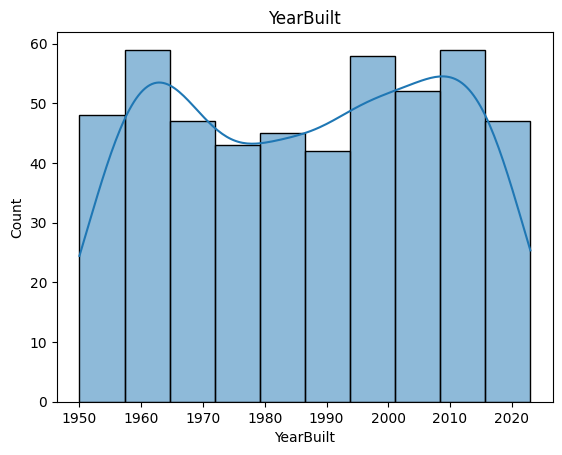

In [237]:
# Check YearBuilt distribution and Plot
# sns.histplot
sns.histplot(df['YearBuilt'], kde=True).set_title('YearBuilt')
print(df['YearBuilt'].min(), df['YearBuilt'].max())

**Step 2: Implementation**
1. Bin `YearBuilt` into meaningful categories (e.g., 'Old', 'Modern', 'New').
2. **Encode the bins** (e.g., Old=0, Modern=1, New=2).
3. **Drop the original `YearBuilt` column**.

**Log your actions**.

In [238]:
# Your Discretization Implementation here
df['HouseLevel'] = pd.cut(df['YearBuilt'], bins=3, labels=[0, 1, 2], right=False, include_lowest=True)
df = df.drop('YearBuilt', axis=1)

log.log_action(
    category='Discretization',
    action='Binning',
    details='Binned YearBuilt into categories: Old, Modern, New',
    columns_affected=['YearBuilt']
)

df.head()

,Price,SqFt,LotSize,Condition,Neighborhood,ZipCode,SqFt_Scaled,LotSize_Robust,NGH_Midtown,NGH_Suburbs,...,ZipCode_1,ZipCode_2,ZipCode_3,ZipCode_4,ZipCode_5,Luxury_Estate,House_Age,SqFt_vs_Overall_Mean,Total_Property_Size,HouseLevel
0,570684.983940,2179.075590,59566.961953,Excellent,Uptown,10044,0.313344,4.931306,False,False,...,0,0,0,0,1,False,8,1.081755,61746.037543,2
1,362813.270878,2010.447483,292037.951766,Good,Midtown,10037,-0.007502,26.560494,True,False,...,0,0,0,1,0,False,63,0.998043,294048.399249,0
2,390796.944648,1833.930920,186450.030474,Good,Suburbs,10020,-0.343356,16.736555,False,True,...,0,0,0,1,1,False,39,0.910415,188283.961394,1
3,350382.575382,2559.824301,21913.263071,Excellent,Midtown,10024,1.037786,1.427992,True,False,...,0,0,1,0,0,False,31,1.270769,24473.087372,1
4,365111.794794,2635.024707,85713.311813,Poor,Downtown,10015,1.180868,7.363972,False,False,...,0,0,1,0,1,False,28,1.308101,88348.336520,1


## Task 6: Feature Selection

**Important:** Remember that `Price` is the target variable. **Exclude `Price` from your feature set (X)** - it should only be used as the target (y) variable.

**Step 1: Correlation Matrix (Filter Method)**
1. Create a correlation matrix for all numerical features (exclude `Price`).
2. Visualize the correlation matrix using a heatmap.
3. Identify and remove features with correlation > 0.8 (or < -0.8) to handle multicollinearity.
4. **Log your action** (features removed).

**Step 2: Wrapper Methods**
Use **three different wrapper methods** to select the top 5 features. Use a `LinearRegression` or `RandomForestRegressor` as the estimator.

1. **Sequential Forward Selection (SFS):** Use `SequentialFeatureSelector` with `direction='forward'`
2. **Sequential Backward Selection (SBS):** Use `SequentialFeatureSelector` with `direction='backward'`
3. **Recursive Feature Elimination (RFE):** Use `RFE`

**Log your actions (features selected by each method).**

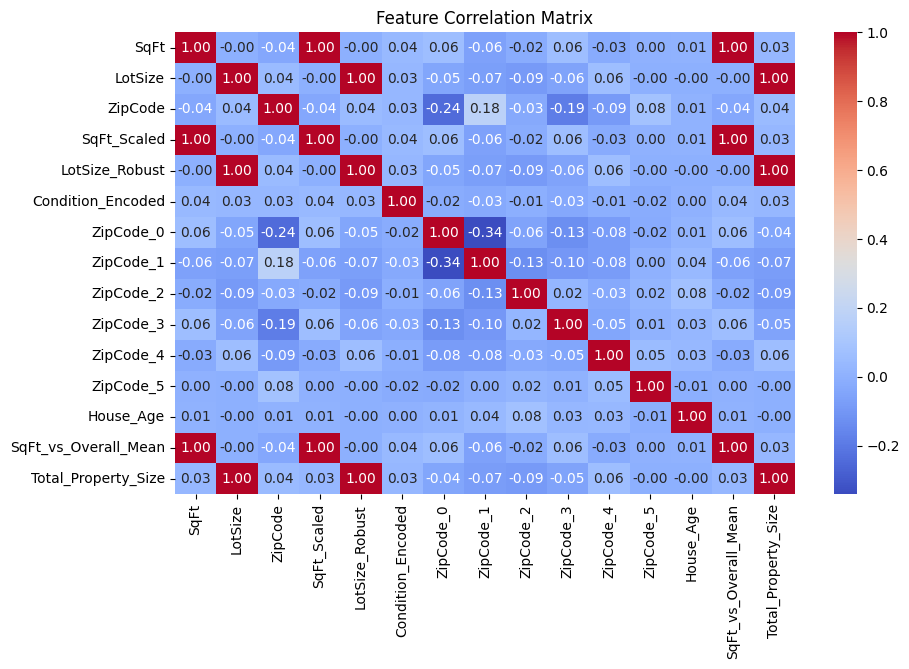

0    570684.983940
1    362813.270878
2    390796.944648
3    350382.575382
4    365111.794794
Name: Price, dtype: float64


,SqFt,LotSize,Condition,Neighborhood,ZipCode,SqFt_Scaled,LotSize_Robust,NGH_Midtown,NGH_Suburbs,NGH_Uptown,...,ZipCode_1,ZipCode_2,ZipCode_3,ZipCode_4,ZipCode_5,Luxury_Estate,House_Age,SqFt_vs_Overall_Mean,Total_Property_Size,HouseLevel
0,2179.075590,59566.961953,Excellent,Uptown,10044,0.313344,4.931306,False,False,True,...,0,0,0,0,1,False,8,1.081755,61746.037543,2
1,2010.447483,292037.951766,Good,Midtown,10037,-0.007502,26.560494,True,False,False,...,0,0,0,1,0,False,63,0.998043,294048.399249,0
2,1833.930920,186450.030474,Good,Suburbs,10020,-0.343356,16.736555,False,True,False,...,0,0,0,1,1,False,39,0.910415,188283.961394,1
3,2559.824301,21913.263071,Excellent,Midtown,10024,1.037786,1.427992,True,False,False,...,0,0,1,0,0,False,31,1.270769,24473.087372,1
4,2635.024707,85713.311813,Poor,Downtown,10015,1.180868,7.363972,False,False,False,...,0,0,1,0,1,False,28,1.308101,88348.336520,1


In [239]:
# Step 1: Correlation Matrix
# Your Correlation Matrix Implementation here
target = df['Price']
df = df.drop('Price', axis=1)

numerical_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Feature Correlation Matrix")
plt.show()

print(target.head())
df.head()

In [240]:
df = df.drop('SqFt', axis=1)
df = df.drop('LotSize', axis=1)
df = df.drop('SqFt_vs_Overall_Mean', axis=1)
df = df.drop('Total_Property_Size', axis=1)

df.head()

,Condition,Neighborhood,ZipCode,SqFt_Scaled,LotSize_Robust,NGH_Midtown,NGH_Suburbs,NGH_Uptown,Condition_Encoded,ZipCode_0,ZipCode_1,ZipCode_2,ZipCode_3,ZipCode_4,ZipCode_5,Luxury_Estate,House_Age,HouseLevel
0,Excellent,Uptown,10044,0.313344,4.931306,False,False,True,3.0,0,0,0,0,0,1,False,8,2
1,Good,Midtown,10037,-0.007502,26.560494,True,False,False,2.0,0,0,0,0,1,0,False,63,0
2,Good,Suburbs,10020,-0.343356,16.736555,False,True,False,2.0,0,0,0,0,1,1,False,39,1
3,Excellent,Midtown,10024,1.037786,1.427992,True,False,False,3.0,0,0,0,1,0,0,False,31,1
4,Poor,Downtown,10015,1.180868,7.363972,False,False,False,0.0,0,0,0,1,0,1,False,28,1


**Answer:** 
- Drop SqFt and SqFt_vs_Overall_Mean && Drop LotSize and Total_Property_Size
- keep SqFt_Scaled since SqFt_Scaled is already normalized for a model
- LotSize_Robust keep the robust version (which handles outliers better)

In [241]:
# Step 2: Wrapper Methods
# Your Wrapper Methods Implementation here
df = df.drop('Condition', axis=1)
df = df.drop('ZipCode', axis=1)
df = df.drop('Neighborhood', axis=1)

from sklearn.linear_model import LinearRegression

X = df
y = target

In [242]:
from sklearn.feature_selection import SequentialFeatureSelector

# --- Using SequentialFeatureSelector (Automated) ---
print("\n--- Automated SequentialFeatureSelector ---")

# 1. Forward Selection
sfs_forward = SequentialFeatureSelector(
    LinearRegression(), 
    n_features_to_select=5, 
    direction='forward'
)
sfs_forward.fit(X, y)
print("Top 5 Features Selected (Forward SFS):", X.columns[sfs_forward.get_support()].tolist())

best_features = X.columns[sfs_forward.get_support()].tolist()
log.log_action(
    category='Feature Selection',
    action='sfs_forward',
    details=f'sfs_forward selected optimal number of features: {sfs_forward.n_features_to_select}. Best features obtained: {best_features}',
    columns_affected=best_features,
    rows_affected=0
)


# 2. Backward Elimination
sfs_backward = SequentialFeatureSelector(
    LinearRegression(), 
    n_features_to_select=5, 
    direction='backward'
)
sfs_backward.fit(X, y)
print("Top 5 Features Selected (Backward SFS):", X.columns[sfs_backward.get_support()].tolist())

best_features = X.columns[sfs_backward.get_support()].tolist()
log.log_action(
    category='Feature Selection',
    action='sfs_backward',
    details=f'sfs_backward selected optimal number of features: {sfs_backward.n_features_to_select}. Best features obtained: {best_features}',
    columns_affected=best_features,
    rows_affected=0
)



--- Automated SequentialFeatureSelector ---
Top 5 Features Selected (Forward SFS): ['LotSize_Robust', 'NGH_Midtown', 'Condition_Encoded', 'ZipCode_3', 'ZipCode_4']
Top 5 Features Selected (Backward SFS): ['LotSize_Robust', 'NGH_Midtown', 'Condition_Encoded', 'ZipCode_3', 'ZipCode_4']


In [243]:
from sklearn.feature_selection import RFE

rfe = RFE(estimator=LinearRegression(), n_features_to_select=5)
rfe.fit(X, y)

print("--- RFE (Select 5) Results ---")
print("Top 5 Features:", X.columns[rfe.support_].tolist())

# Log the feature selection results
best_features = X.columns[rfe.support_].tolist()
log.log_action(
    category='Feature Selection',
    action='RFE',
    details=f'RFE selected optimal number of features: {rfe.n_features_}. Best features obtained: {best_features}',
    columns_affected=best_features,
    rows_affected=0
)

--- RFE (Select 5) Results ---
Top 5 Features: ['SqFt_Scaled', 'NGH_Midtown', 'ZipCode_0', 'ZipCode_3', 'ZipCode_4']


## Task 7: Documentation
Print the full df cleaning log as a DataFrame.

In [244]:
display(log.to_dataframe())

,timestamp,category,action,details,rows_affected,columns_affected,before_value,after_value
0,2026-03-25 21:48:10,Scaling,StandardScaler,Applied Z-Score standardization to SqFt (Norma...,NaN,[SqFt],None,NaN
1,2026-03-25 21:48:10,Scaling,RobustScaler,Applied Robust Scaling to LotSize to handle ou...,NaN,[LotSize],None,NaN
2,2026-03-25 21:48:12,Encoding,One-Hot Encoding,One-Hot encoded Neighborhood column.,NaN,[Neighborhood],None,Created 3 new columns
3,2026-03-25 21:48:12,Encoding,Ordinal Encoding,Encoded Condition preserving ordinality.,NaN,[Condition],None,NaN
4,2026-03-25 21:48:12,Encoding,Binary Encoding,Binary encoded ZipCode (High Cardinality).,NaN,[ZipCode],None,Created 6 columns
5,2026-03-25 21:48:12,Feature Interaction,Create a binary flag called `Luxury_Estate`,Define it as a property that has `Condition` =...,NaN,[Luxury_Estate],None,NaN
6,2026-03-25 21:48:12,Feature Interaction,Create a feature,`House_Age` = Current Year - `YearBuilt`,NaN,[House_Age],None,NaN
7,2026-03-25 21:48:12,Feature Interaction,Create a feature that shows how each houses sq...,`SqFt_vs_Overall_Mean` = `SqFt` / mean(`SqFt`),NaN,[SqFt_vs_Overall_Mean],None,NaN
8,2026-03-25 21:48:12,Feature Interaction,Create a feature,`Total_Property_Size` = `SqFt` + `LotSize`,NaN,[Total_Property_Size],None,NaN
9,2026-03-25 21:48:13,Discretization,Binning,"Binned YearBuilt into categories: Old, Modern,...",NaN,[YearBuilt],None,NaN
